# Selling Growth vs. Selling Scarcity: WNBA & NBA Fan Demand, 2015–2026

**Author:** Chaz Colucci · Sport Management, NC State
**Question:** What is actually driving the WNBA attendance boom, how does it compare with the NBA, and what does that mean for a brand deciding where to put its sponsorship money?

**Data:** Game-level regular-season attendance from ESPN, via the open-source [sportsdataverse](https://github.com/sportsdataverse) projects (`wehoop-wnba-data`, `hoopR-nba-data`), plus WNBA player box scores, which are used to tag every game Caitlin Clark played in or missed.

| League | Seasons used | Excluded and why |
|---|---|---|
| WNBA | 2019, 2022–2026 | 2020 (bubble, no fans), 2021 (COVID capacity limits), All-Star games |
| NBA | 2015–2019, 2022–2026 | 2020 bubble, 2021 limited crowds, neutral-site and international games |

**Plan.** Every hypothesis below was written down before testing:
1. Data checks (SQL)
2. Eight hypothesis tests, with a Benjamini–Hochberg correction across all of them
3. Replication on the 2026 season
4. A two-stage attendance model, trained on 2022–2025 and tested on 2026
5. What it means for a beverage-category sponsor

A "How I used AI" note is at the end.

In [1]:
import json, sqlite3, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.stats.multitest import multipletests
from sklearn.linear_model import Ridge
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, roc_auc_score
warnings.filterwarnings('ignore')
pd.set_option('display.width', 140)

WNBA_C, NBA_C, GRAY, INK, INK2 = '#eb6834', '#2a78d6', '#b5b4ad', '#0b0b0b', '#52514e'
plt.rcParams.update({'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'axes.edgecolor': '#d6d5d0',
                     'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 11, 'axes.titleweight': 'bold', 'axes.titlesize': 13,
                     'axes.grid': True, 'grid.color': '#ecebe7', 'grid.linewidth': 0.8, 'axes.axisbelow': True})
R = {}   # every number quoted in the README / deck is stored here and written to results.json

con = sqlite3.connect('data/attendance.db')
w = pd.read_sql('SELECT * FROM wnba_games', con)
n = pd.read_sql('SELECT * FROM nba_games', con)
print(len(w), 'WNBA games |', len(n), 'NBA games')

1512 WNBA games | 12242 NBA games


## 1. Data checks (SQL)
Before any analysis, I confirm that the tables contain what I think they contain: game counts per season, missing attendance, duplicate games, and attendance values that fall outside a plausible range.

In [2]:
q = lambda s: pd.read_sql(s, con)
checks = {
 'WNBA games per season': q('''SELECT season, COUNT(*) AS games, ROUND(AVG(attendance)) AS avg_att,
                                      MIN(attendance) AS min_att, MAX(attendance) AS max_att
                               FROM wnba_games GROUP BY season ORDER BY season'''),
 'Duplicate game ids': q('''SELECT 'wnba' AS lg, COUNT(*) - COUNT(DISTINCT game_id) AS dupes FROM wnba_games
                            UNION ALL SELECT 'nba', COUNT(*) - COUNT(DISTINCT game_id) FROM nba_games'''),
 'Null / zero attendance': q('''SELECT 'wnba' AS lg, SUM(attendance IS NULL OR attendance <= 0) AS bad FROM wnba_games
                                UNION ALL SELECT 'nba', SUM(attendance IS NULL OR attendance <= 0) FROM nba_games'''),
 'Clark games tagged': q('''SELECT season, SUM(clark_played) AS clark_played, SUM(fever_no_clark) AS fever_without_clark,
                                   SUM(fever_game) AS fever_games
                            FROM wnba_games WHERE season >= 2024 GROUP BY season'''),
}
for k, v in checks.items():
    print('\n--', k); print(v.to_string(index=False))
R['wnba_games'] = len(w); R['nba_games'] = len(n)
assert checks['Duplicate game ids'].dupes.sum() == 0 and checks['Null / zero attendance'].bad.sum() == 0
ct = checks['Clark games tagged']
assert (ct.clark_played + ct.fever_without_clark == ct.fever_games).all(), 'every Fever game must be tagged'
R['clark_played'] = dict(zip(ct.season.astype(str), ct.clark_played.astype(int)))
R['clark_missed_2025'] = int(ct.set_index('season').loc[2025, 'fever_without_clark'])


-- WNBA games per season
 season  games  avg_att  min_att  max_att
   2019    204   6528.0   1181.0  17934.0
   2022    212   5695.0    960.0  18100.0
   2023    241   6617.0   2394.0  17406.0
   2024    241   9796.0   3255.0  20711.0
   2025    286  10987.0   3265.0  20409.0
   2026    328  11471.0   3575.0  20996.0

-- Duplicate game ids
  lg  dupes
wnba      0
 nba      0

-- Null / zero attendance
  lg  bad
wnba    0
 nba    0

-- Clark games tagged
 season  clark_played  fever_without_clark  fever_games
   2024            40                    0           40
   2025            13                   32           45
   2026            40                    4           44


**Result:** no duplicates and no missing attendance after cleaning. Every Fever game from 2024 on is tagged as either Clark played or Clark did not play. The highest WNBA crowd (about 21,000) and the lowest (about 1,000) are both plausible.

A note on capacity: ESPN doesn't publish arena capacity. As a **capacity proxy** I use each team's 99th-percentile crowd in its main arena that season, and I call a game "full" when it reaches at least 98% of that. This understates how much room a team has to grow when it never sells out, so I treat fill rates as relative, not exact.

## 2. The big picture: two leagues on different curves

        WNBA avg  NBA avg  WNBA fill  NBA fill
season                                        
2015         NaN  17825.0        NaN     0.923
2016         NaN  17863.0        NaN     0.920
2017         NaN  17880.0        NaN     0.921
2018         NaN  17973.0        NaN     0.934
2019      6528.0  17851.0      0.693     0.931
2022      5695.0  17171.0      0.668     0.904
2023      6617.0  18038.0      0.728     0.943
2024      9796.0  18330.0      0.800     0.962
2025     10987.0  18152.0      0.864     0.952
2026     11471.0  18105.0      0.868     0.953


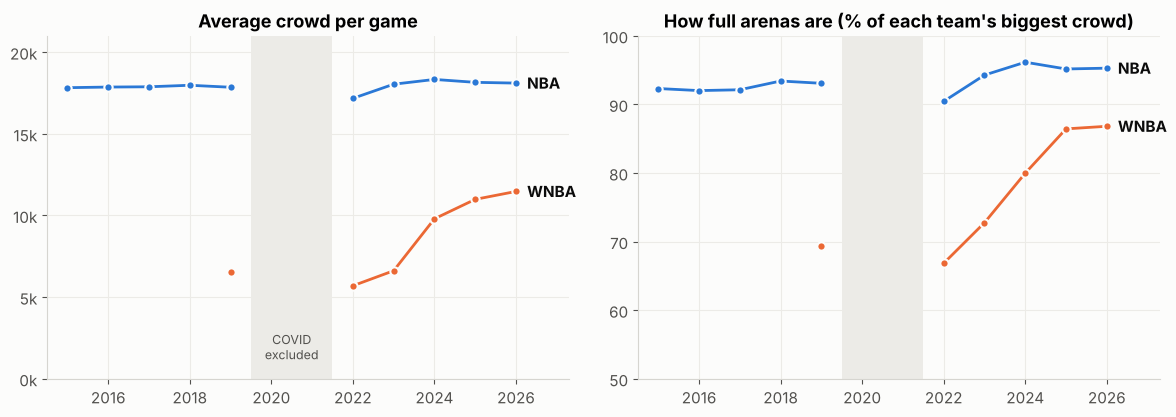

In [3]:
wl = w.groupby('season').attendance.mean(); nl = n.groupby('season').attendance.mean()
wf = w.groupby('season').fill_rate.mean(); nf = n.groupby('season').fill_rate.mean()
R['wnba_avg'] = {str(k): round(v) for k, v in wl.items()}
R['nba_avg'] = {str(k): round(v) for k, v in nl.items()}
R['wnba_fill'] = {str(k): round(v, 3) for k, v in wf.items()}
R['nba_fill'] = {str(k): round(v, 3) for k, v in nf.items()}
R['wnba_growth_2023_2026'] = round(wl[2026] / wl[2023] - 1, 3)
R['nba_growth_2019_2026'] = round(nl[2026] / nl[2019] - 1, 3)
print(pd.DataFrame({'WNBA avg': wl.round(0), 'NBA avg': nl.round(0), 'WNBA fill': wf.round(3), 'NBA fill': nf.round(3)}))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
for s, c, lab in [(nl, NBA_C, 'NBA'), (wl, WNBA_C, 'WNBA')]:
    for seg in [s[s.index <= 2019], s[s.index >= 2022]]:
        ax[0].plot(seg.index, seg.values, color=c, lw=2, marker='o', ms=6, mec='#fcfcfb', mew=1.5)
    ax[0].annotate(lab, (s.index[-1], s.values[-1]), xytext=(8, 0), textcoords='offset points', color=INK, va='center', fontweight='bold')
ax[0].set_title('Average crowd per game'); ax[0].set_ylim(0, 21000); ax[0].set_xlim(2014.5, 2027.3)
ax[0].set_yticks(range(0, 20001, 5000)); ax[0].yaxis.set_major_formatter(lambda v, p: f'{v/1000:.0f}k')
ax[0].axvspan(2019.5, 2021.5, color='#ecebe7', lw=0); ax[0].text(2020.5, 1200, 'COVID\nexcluded', ha='center', color=INK2, fontsize=9)
for s, c, lab in [(nf, NBA_C, 'NBA'), (wf, WNBA_C, 'WNBA')]:
    for seg in [s[s.index <= 2019], s[s.index >= 2022]]:
        ax[1].plot(seg.index, seg.values * 100, color=c, lw=2, marker='o', ms=6, mec='#fcfcfb', mew=1.5)
    ax[1].annotate(lab, (s.index[-1], s.values[-1] * 100), xytext=(8, 0), textcoords='offset points', color=INK, va='center', fontweight='bold')
ax[1].set_title('How full arenas are (% of each team\'s biggest crowd)'); ax[1].set_ylim(50, 100); ax[1].set_xlim(2014.5, 2027.3)
ax[1].axvspan(2019.5, 2021.5, color='#ecebe7', lw=0)
plt.tight_layout(); plt.savefig('chart_1_two_curves.png', dpi=160); plt.show()

**Reading the charts:** the NBA has been flat at about 18,000 per game for a decade and sits around 95% full. It's selling **scarce** inventory. The WNBA's average crowd grew about 73% from 2023 to 2026 and went from roughly 70% to about 87% full. It's selling **growth**.

## 3. Hypothesis tests
**Definition: Fever road lift.** For a Fever road game, the lift is attendance divided by the home team's average crowd in its *non-Fever* home games that same season, minus 1. This controls for the fact that some markets are simply bigger than others.

| # | Hypothesis (written before testing) | Test |
|---|---|---|
| H1 | Fever road lift was larger in 2024 (Clark's rookie year) than in 2023 | Mann–Whitney, one-sided |
| H2 | In 2025, Fever road games drew more when Clark played than when she sat | Home-team fixed-effects regression on log attendance |
| H3 | Fever road lift stayed above zero in Aug–Sep 2025, after fans knew Clark was out | Wilcoxon signed-rank vs 0 |
| H4 | Non-Fever crowds grew 2023→2025 within the same team (growth isn't one player) | Wilcoxon signed-rank on team-level % change |
| H5 | NBA crowds changed between 2015–19 and 2023–26 within the same team | Wilcoxon signed-rank, two-sided |
| H6 | WNBA games on major national TV draw bigger crowds | Team-season fixed-effects regression |
| H7 | WNBA weekend (Fri–Sun) games draw bigger crowds | Same regression |
| H8 | NBA weekend games draw bigger crowds | Team-season fixed-effects regression |

With 8 tests, a few could look significant by luck alone, so I apply a **Benjamini–Hochberg** correction across all of them and judge each one by its adjusted p-value.

*Caveat for H6:* networks choose the biggest games to broadcast, so the TV effect is an association, not proof that TV causes bigger crowds.

In [4]:
base = (w[w.fever_game == 0].groupby(['season', 'home_display_name']).attendance.mean().rename('base_nonfever'))
w = w.join(base, on=['season', 'home_display_name'])
road = w[(w.fever_away == 1)].copy()
road['lift'] = road.attendance / road.base_nonfever - 1
road['phase'] = np.where(road.season < 2024, 'pre-Clark', np.where(road.clark_played == 1, 'Clark played',
                 np.where(road.game_date < '2025-08-01', 'Clark out (early)', 'Clark out (Aug-Sep)')))
lift_by_season = road.groupby('season').lift.agg(['median', 'mean', 'count'])
print(lift_by_season.round(3))
R['fever_road_lift_median'] = {str(k): round(v, 3) for k, v in lift_by_season['median'].items()}
r25 = road[road.season == 2025]
ph = r25.groupby('phase').lift.agg(['median', 'mean', 'count']); print(ph.round(3))
R['road_2025_phase_median'] = {k: round(v, 3) for k, v in ph['median'].items()}
R['road_2025_phase_n'] = {k: int(v) for k, v in ph['count'].items()}

tests = []
# H1
a, b = road[road.season == 2024].lift, road[road.season == 2023].lift
p = stats.mannwhitneyu(a, b, alternative='greater').pvalue
tests.append(('H1', 'Fever road lift 2024 > 2023', f'median {a.median():+.0%} vs {b.median():+.0%}', p))
# H2: fixed-effects regression, 2025 games only
g25 = w[(w.season == 2025) & (w.neutral_site == 0)].copy(); g25['log_att'] = np.log(g25.attendance)
g25['clark_away'] = ((g25.fever_away == 1) & (g25.clark_played == 1)).astype(int)
g25['noclark_away'] = ((g25.fever_away == 1) & (g25.clark_played == 0)).astype(int)
m2 = smf.ols('log_att ~ C(home_display_name) + clark_away + noclark_away + weekend + major_tv + C(month)', g25).fit(cov_type='HC3')
d = m2.t_test('clark_away - noclark_away = 0')
diff = float(np.atleast_1d(d.effect)[0]); p2 = float(np.atleast_1d(d.pvalue)[0])
R['h2_clark_road_premium'] = round(np.exp(m2.params.clark_away) - 1, 3)
R['h2_noclark_road_premium'] = round(np.exp(m2.params.noclark_away) - 1, 3)
R['h2_with_vs_without'] = round(np.exp(diff) - 1, 3)
tests.append(('H2', '2025: road crowds bigger with Clark than without',
              f"with {R['h2_clark_road_premium']:+.0%}, without {R['h2_noclark_road_premium']:+.0%} vs normal; gap {R['h2_with_vs_without']:+.0%}", p2))
# H3
late = r25[r25.phase == 'Clark out (Aug-Sep)']
p = stats.wilcoxon(np.log1p(late.lift), alternative='greater').pvalue
tests.append(('H3', 'Aug-Sep 2025 (Clark out) lift > 0', f'median {late.lift.median():+.0%}, n={len(late)}', p))
# H4
t = w[w.fever_game == 0].groupby(['home_display_name', 'season']).attendance.mean().unstack()
chg = (t[2025] / t[2023] - 1).dropna()
p = stats.wilcoxon(chg, alternative='two-sided').pvalue
R['h4_teams'] = int(len(chg)); R['h4_teams_up'] = int((chg > 0).sum()); R['h4_median_chg'] = round(chg.median(), 3)
nfmean = w[w.fever_game == 0].groupby('season').attendance.mean()
R['nonfever_avg'] = {str(k): round(v) for k, v in nfmean.items()}
tests.append(('H4', 'Non-Fever crowds grew 2023->2025 (same teams)', f'median team {chg.median():+.0%}; {R["h4_teams_up"]}/{len(chg)} teams up', p))
# H5
n['era'] = np.where(n.season <= 2019, 'pre', np.where(n.season >= 2023, 'post', 'mid'))
nt = n[n.era != 'mid'].groupby(['home_display_name', 'era']).attendance.mean().unstack().dropna()
dn = nt['post'] / nt['pre'] - 1
p = stats.wilcoxon(dn).pvalue
R['h5_median_chg'] = round(dn.median(), 4); R['h5_teams'] = int(len(dn))
tests.append(('H5', 'NBA crowds changed 2015-19 -> 2023-26 (same teams)', f'median team {dn.median():+.1%}', p))
# H6, H7: WNBA 2022-2026 team-season fixed effects
wf_ = w[(w.season >= 2022) & (w.neutral_site == 0)].copy(); wf_['log_att'] = np.log(wf_.attendance)
wf_['ts'] = wf_.home_display_name + wf_.season.astype(str)
m6 = smf.ols('log_att ~ C(ts) + major_tv + weekend + fever_away + C(month)', wf_).fit(cov_type='HC3')
R['h6_tv_premium'] = round(np.exp(m6.params.major_tv) - 1, 3); R['h7_weekend_premium'] = round(np.exp(m6.params.weekend) - 1, 3)
tests.append(('H6', 'WNBA major national TV games draw more', f"{R['h6_tv_premium']:+.1%}", m6.pvalues.major_tv))
tests.append(('H7', 'WNBA weekend games draw more', f"{R['h7_weekend_premium']:+.1%}", m6.pvalues.weekend))
# H8
nn = n[n.season >= 2022].copy(); nn['log_att'] = np.log(nn.attendance); nn['ts'] = nn.home_display_name + nn.season.astype(str)
m8 = smf.ols('log_att ~ C(ts) + weekend + national_tv + C(month)', nn).fit(cov_type='HC3')
R['h8_nba_weekend_premium'] = round(np.exp(m8.params.weekend) - 1, 4)
tests.append(('H8', 'NBA weekend games draw more', f"{R['h8_nba_weekend_premium']:+.1%}", m8.pvalues.weekend))

T = pd.DataFrame(tests, columns=['id', 'hypothesis', 'estimate', 'p_raw'])
T['p_bh'] = multipletests(T.p_raw, method='fdr_bh')[1]
T['significant_after_correction'] = T.p_bh < 0.05
pd.set_option('display.max_colwidth', 70)
print(T.assign(p_raw=T.p_raw.map('{:.2g}'.format), p_bh=T.p_bh.map('{:.2g}'.format)).to_string(index=False))
R['tests'] = T.assign(p_raw=T.p_raw.round(6), p_bh=T.p_bh.round(6)).to_dict('records')
T.to_csv('tests.csv', index=False)

        median   mean  count
season                      
2019    -0.089 -0.087     17
2022    -0.149 -0.140     18
2023    -0.009  0.155     20
2024     0.705  1.135     20
2025     0.557  0.813     23
2026     0.322  0.484     22
                     median   mean  count
phase                                    
Clark out (Aug-Sep)   0.409  0.582     10
Clark out (early)     0.844  0.861      8
Clark played          0.656  1.200      5


id                                         hypothesis                                     estimate   p_raw    p_bh  significant_after_correction
H1                        Fever road lift 2024 > 2023                           median +71% vs -1% 0.00031 0.00083                          True
H2   2025: road crowds bigger with Clark than without with +109%, without +59% vs normal; gap +32%    0.39    0.45                         False
H3                  Aug-Sep 2025 (Clark out) lift > 0                            median +41%, n=10   0.002  0.0031                          True
H4      Non-Fever crowds grew 2023->2025 (same teams)             median team +25%; 11/11 teams up 0.00098   0.002                          True
H5 NBA crowds changed 2015-19 -> 2023-26 (same teams)                            median team -0.2%    0.61    0.61                         False
H6             WNBA major national TV games draw more                                        +3.3%   0.037    0.05                

**What the tests say**

- **H1 (supported).** Fever road games went from ordinary crowds to some of the biggest in the league the year Clark arrived.
- **H2 (not supported).** In 2025, Fever road games drew far more than normal *whether or not Clark played*, and the gap between the two is not statistically significant. One reason is timing: fans buy tickets weeks ahead, and teams had already moved several of these games into bigger arenas. That makes this a test of a "Fever brand" effect, not only a Clark effect.
- **H3 (supported).** Even late in 2025, when everyone knew she was out for the season, Fever road crowds stayed well above normal. *The demand transferred from the player to the team.*
- **H4 (supported).** Growth is league-wide. Every comparable team grew its non-Fever crowds.
- **H5 (no change).** NBA crowds within the same team are flat. The NBA can't add seats, so its growth has to come from price, premium seating and partnerships.
- **H6–H8.** Weekend games draw about 7% more in the WNBA and about 3% more in the NBA. The WNBA national TV premium (about 3%) only *barely* survives the correction (adjusted p ≈ 0.0499), so I treat it as weak evidence. These are useful for scheduling activations, but much smaller than the matchup effect.

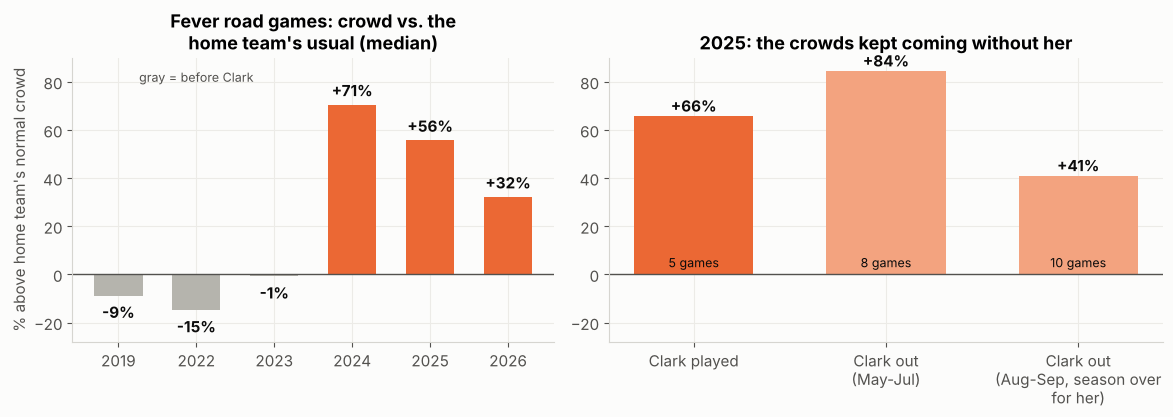

Fever road games moved to a bigger arena (2024-26): 20; avg crowd 17,931 vs those teams' usual 6,822


In [5]:
order = ['pre-Clark', 'Clark played', 'Clark out (early)', 'Clark out (Aug-Sep)']
seasons_m = road.groupby('season').lift.median()
fig, ax = plt.subplots(1, 2, figsize=(12, 4.3), gridspec_kw={'width_ratios': [1, 1.15]})
cols = [GRAY if s < 2024 else WNBA_C for s in seasons_m.index]
ax[0].bar(seasons_m.index.astype(str), seasons_m.values * 100, color=cols, width=0.62)
for i, v in enumerate(seasons_m.values):
    ax[0].text(i, v * 100 + (2 if v >= 0 else -3), f'{v:+.0%}', ha='center', va='bottom' if v >= 0 else 'top', color=INK, fontweight='bold')
ax[0].axhline(0, color=INK2, lw=1); ax[0].set_title('Fever road games: crowd vs. the\nhome team\'s usual (median)')
ax[0].set_ylabel('% above home team\'s normal crowd'); ax[0].set_ylim(-28, 90)
ax[0].text(1, 80, 'gray = before Clark', ha='center', color=INK2, fontsize=9)
p25 = road[road.season == 2025].groupby('phase').lift.median().reindex(order[1:])
nn_ = road[road.season == 2025].groupby('phase').size().reindex(order[1:])
ax[1].bar(range(3), p25.values * 100, color=[WNBA_C, '#f3a37f', '#f3a37f'], width=0.62)
for i, (v, k) in enumerate(zip(p25.values, nn_.values)):
    ax[1].text(i, v * 100 + 2, f'{v:+.0%}', ha='center', color=INK, fontweight='bold')
    ax[1].text(i, 3, f'{k} games', ha='center', color=INK, fontsize=9)
ax[1].set_xticks(range(3)); ax[1].set_xticklabels(['Clark played', 'Clark out\n(May-Jul)', 'Clark out\n(Aug-Sep, season over\nfor her)'])
ax[1].axhline(0, color=INK2, lw=1); ax[1].set_title('2025: the crowds kept coming without her'); ax[1].set_ylim(-28, 90)
plt.tight_layout(); plt.savefig('chart_2_fever_effect.png', dpi=160); plt.show()

reloc = w[(w.relocated == 1) & (w.season >= 2024) & (w.fever_home == 0)]
R['relocated_2024_2026'] = int(len(reloc)); R['relocated_fever_away'] = int(reloc.fever_away.sum())
big = road[(road.relocated == 1) & (road.season >= 2024)][['season', 'home_display_name', 'venue_full_name', 'attendance', 'base_nonfever']]
R['relocated_fever_avg_att'] = round(big.attendance.mean()); R['relocated_fever_home_base_avg'] = round(big.base_nonfever.mean())
print(f"Fever road games moved to a bigger arena (2024-26): {len(big)}; avg crowd {big.attendance.mean():,.0f} vs those teams' usual {big.base_nonfever.mean():,.0f}")

### Replication on 2026, a season the tests never saw
A finding is stronger if it holds up on new data. 2026 was not used to form any hypothesis, so I re-run H1 and H4 on it.

In [6]:
a26 = road[road.season == 2026].lift
rep1 = stats.wilcoxon(np.log1p(a26), alternative='greater').pvalue
chg26 = (t[2026] / t[2023] - 1).dropna()
rep4 = stats.wilcoxon(chg26).pvalue
R['rep_2026_fever_road_lift_median'] = round(a26.median(), 3); R['rep_2026_fever_road_p'] = round(rep1, 6)
R['rep_2026_nonfever_chg_median'] = round(chg26.median(), 3); R['rep_2026_teams_up'] = int((chg26 > 0).sum()); R['rep_2026_teams'] = int(len(chg26))
print(f'2026 Fever road lift: median {a26.median():+.0%} (p={rep1:.2g}) - still positive, but shrinking as the rest of the league catches up')
print(f'2026 vs 2023 non-Fever crowds: median team {chg26.median():+.0%}, {(chg26>0).sum()}/{len(chg26)} teams up (p={rep4:.2g})')

ex = w[(w.expansion_team == 1)].groupby(['season', 'home_display_name']).agg(avg=('attendance', 'mean'), games=('attendance', 'size'), fill=('fill_rate', 'mean'))
print('\nExpansion teams:'); print(ex.round(2))
R['expansion'] = {f'{s} {h}': {'avg': round(r.avg), 'games': int(r.games)} for (s, h), r in ex.iterrows()}

2026 Fever road lift: median +32% (p=0.001) - still positive, but shrinking as the rest of the league catches up
2026 vs 2023 non-Fever crowds: median team +39%, 11/11 teams up (p=0.00098)

Expansion teams:
                                    avg  games  fill
season home_display_name                            
2025   Golden State Valkyries  18064.00     22  1.00
2026   Golden State Valkyries  18064.00     21  1.00
       Portland Fire           14516.19     21  0.73
       Toronto Tempo           10828.41     22  1.00


## 4. Model: which games will draw the biggest crowds?
A sponsor plans activations months ahead (sampling tents, giveaways, branded nights), so the useful question is: **given next season's schedule, which games will be the biggest?** I split the forecast into two stages:

- **Stage 1, season level:** how big a team's average crowd will be. Candidates are a naive "same as last season" forecast and a ridge regression.
- **Stage 2, game level:** how much bigger or smaller a given game will be than that team's average. This uses only information known when the schedule is released: the opponent's past road draw, whether it's a Fever road game, national TV, weekend, a move to a bigger arena, and summer dates.

**Train:** 2022–2025. **Test:** the full 2026 season, including two first-year teams. Predictions are capped at the largest crowd previously recorded at that arena in either league, using the NBA data, because a building can't hold more people than it holds.

In [7]:
m = w[w.neutral_site == 0].copy()
seasons = sorted(m.season.unique()); prev = {s: seasons[i - 1] for i, s in enumerate(seasons) if i > 0}
home_avg = m.groupby(['season', 'home_display_name']).attendance.mean()
league = m.groupby('season').attendance.mean()
m['home_avg'] = [home_avg[(s, h)] for s, h in zip(m.season, m.home_display_name)]
m['prior_league'] = m.season.map(lambda s: league.get(prev.get(s), np.nan))
m['prior_home'] = [home_avg.get((prev.get(s), h), np.nan) for s, h in zip(m.season, m.home_display_name)]
m['new_team'] = m.prior_home.isna().astype(int); m['prior_home'] = m.prior_home.fillna(m.prior_league)
m['ratio'] = m.attendance / m.home_avg
draw = m.groupby(['season', 'away_display_name']).ratio.mean()
m['opp_draw_prior'] = [draw.get((prev.get(s), a), 1.0) for s, a in zip(m.season, m.away_display_name)]
m['fever_road'] = m.fever_away
m['summer'] = m.month.isin([6, 7, 8]).astype(int)
# venue capacity known before the season: biggest crowd ever recorded there earlier, either league
allv = pd.concat([w[['season', 'venue_full_name', 'attendance']], n[['season', 'venue_full_name', 'attendance']]])
vmax = allv.groupby(['venue_full_name', 'season']).attendance.max()
def vcap(s, v):
    if v not in vmax.index.get_level_values(0): return np.nan
    x = vmax.loc[v]; x = x[x.index < s]
    return x.max() if len(x) else np.nan
m['venue_cap'] = [vcap(s, v) for s, v in zip(m.season, m.venue_full_name)]
m['prior_fill'] = (m.prior_home / m.venue_cap).clip(upper=1).fillna(0.6)
cap = lambda p, c: np.where(np.isnan(c), p, np.minimum(p, c))

train = m[(m.season >= 2022) & (m.season <= 2025)].copy(); test = m[m.season == 2026].copy()

# ---- Stage 1: season level (one row per team-season)
ts = m.groupby(['season', 'home_display_name']).agg(y=('home_avg', 'first'), prior=('prior_home', 'first'),
        new=('new_team', 'first'), lg=('prior_league', 'first')).reset_index()
ts['lgrowth'] = ts.season.map(lambda s: np.log(league.get(prev.get(s), np.nan) / league.get(prev.get(prev.get(s)), np.nan)) if prev.get(prev.get(s)) else 0)
ts['target'] = np.log(ts.y / ts.prior)
s_tr, s_te = ts[(ts.season >= 2023) & (ts.season <= 2025)], ts[ts.season == 2026].copy()
r1 = Ridge(alpha=1.0).fit(s_tr[['new', 'lgrowth']], s_tr.target)
s_te['ridge'] = s_te.prior * np.exp(r1.predict(s_te[['new', 'lgrowth']]))
s1_naive = mean_absolute_error(s_te.y, s_te.prior); s1_ridge = mean_absolute_error(s_te.y, s_te.ridge)
R['stage1_mae_naive'] = round(s1_naive); R['stage1_mae_ridge'] = round(s1_ridge)
print(f'Stage 1 (team season average, 2026, {len(s_te)} teams) MAE: naive {s1_naive:,.0f} | ridge {s1_ridge:,.0f}')

# ---- Stage 2: game level, relative to the team's season average
F = ['opp_draw_prior', 'fever_road', 'major_tv', 'weekend', 'relocated', 'summer', 'prior_fill']
train['y2'] = np.log(train.ratio)
ridge = Ridge(alpha=1.0).fit(train[F], train.y2)
gbm = GradientBoostingRegressor(random_state=0, n_estimators=300, max_depth=3, learning_rate=0.03, subsample=0.8).fit(train[F], train.y2)
test['mult_ridge'] = np.exp(ridge.predict(test[F])); test['mult_gbm'] = np.exp(gbm.predict(test[F]))
test['top10'] = (test.ratio >= test.ratio.quantile(0.9)).astype(int)
R['stage2_auc_ridge'] = round(roc_auc_score(test.top10, test.mult_ridge), 3)
R['stage2_auc_gbm'] = round(roc_auc_score(test.top10, test.mult_gbm), 3)
g_base = mean_absolute_error(test.attendance, test.home_avg)
g_ridge = mean_absolute_error(test.attendance, cap(test.home_avg * test.mult_ridge, test.venue_cap.values))
g_gbm = mean_absolute_error(test.attendance, cap(test.home_avg * test.mult_gbm, test.venue_cap.values))
R['stage2_mae_flat'] = round(g_base); R['stage2_mae_ridge'] = round(g_ridge); R['stage2_mae_gbm'] = round(g_gbm)
print(f'Stage 2 (game vs team average, 2026, {len(test)} games) MAE: every game = team average {g_base:,.0f} | ridge {g_ridge:,.0f} | GBM {g_gbm:,.0f}')
print(f"Spotting the top-10% biggest-crowd games in 2026 (AUC): ridge {R['stage2_auc_ridge']} | GBM {R['stage2_auc_gbm']}")
print('Ridge multipliers (x crowd):', {f: round(float(np.exp(c)), 3) for f, c in zip(F, ridge.coef_)})

# ---- Full pipeline: what you could actually have forecast before 2026 tipped off
full_naive = mean_absolute_error(test.attendance, cap(test.prior_home, test.venue_cap.values))
full_model = mean_absolute_error(test.attendance, cap(test.prior_home * test.mult_gbm, test.venue_cap.values))
R['pipeline_mae_naive'] = round(full_naive); R['pipeline_mae_model'] = round(full_model); R['test_mean_att'] = round(test.attendance.mean())
R['test_games'] = int(len(test))
print(f'Full pipeline (last season x game multiplier) MAE: naive {full_naive:,.0f} | model {full_model:,.0f} | avg 2026 crowd {test.attendance.mean():,.0f}')

Stage 1 (team season average, 2026, 15 teams) MAE: naive 872 | ridge 2,836


Stage 2 (game vs team average, 2026, 327 games) MAE: every game = team average 1,795 | ridge 1,431 | GBM 1,408
Spotting the top-10% biggest-crowd games in 2026 (AUC): ridge 0.95 | GBM 0.955
Ridge multipliers (x crowd): {'opp_draw_prior': 1.316, 'fever_road': 1.159, 'major_tv': 1.01, 'weekend': 1.079, 'relocated': 1.432, 'summer': 1.055, 'prior_fill': 0.857}
Full pipeline (last season x game multiplier) MAE: naive 1,752 | model 1,693 | avg 2026 crowd 11,487


             predicted  actual  games
bucket                               
Lowest 20%       0.840   0.883     67
2                0.875   0.886     64
3                0.908   0.905     65
4                0.948   0.979     65
Highest 20%      1.267   1.343     66
Of the 30 games the model ranked highest for 2026, 83% were actually in the top 10% (a random pick would be 10%)


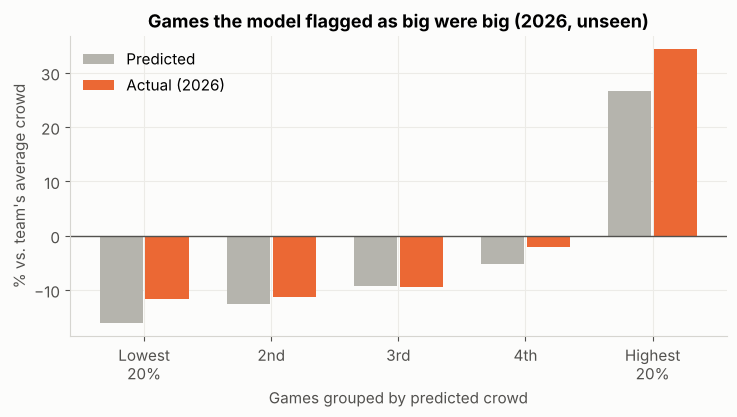

In [8]:
# Calibration of the game-level model: do games predicted to be big actually turn out big?
test['bucket'] = pd.qcut(test.mult_gbm, 5, labels=['Lowest 20%', '2', '3', '4', 'Highest 20%'])
cal = test.groupby('bucket', observed=True).agg(predicted=('mult_gbm', 'mean'), actual=('ratio', 'mean'), games=('ratio', 'size'))
print(cal.round(3)); cal.to_csv('calibration_2026.csv')
R['calibration'] = {str(k): {'pred': round(r.predicted, 3), 'actual': round(r.actual, 3), 'games': int(r.games)} for k, r in cal.iterrows()}
top = test.sort_values('mult_gbm', ascending=False).head(30)
R['top30_hit_rate'] = round(top.top10.mean(), 3)
R['top30_avg_ratio'] = round(top.ratio.mean(), 3)
print(f"Of the 30 games the model ranked highest for 2026, {top.top10.mean():.0%} were actually in the top 10% (a random pick would be 10%)")

fig, ax = plt.subplots(figsize=(7.5, 4.3))
x = np.arange(len(cal))
ax.bar(x - 0.18, (cal.predicted - 1) * 100, width=0.34, color=GRAY, label='Predicted')
ax.bar(x + 0.18, (cal.actual - 1) * 100, width=0.34, color=WNBA_C, label='Actual (2026)')
ax.axhline(0, color=INK2, lw=1); ax.set_xticks(x); ax.set_xticklabels(['Lowest\n20%', '2nd', '3rd', '4th', 'Highest\n20%'])
ax.set_ylabel('% vs. team\'s average crowd'); ax.set_title('Games the model flagged as big were big (2026, unseen)')
ax.set_xlabel('Games grouped by predicted crowd'); ax.legend(frameon=False, loc='upper left')
plt.tight_layout(); plt.savefig('chart_3_model_calibration.png', dpi=160); plt.show()

**Model takeaways**

- **Season level:** with a league changing this fast, a simple "same as last year" forecast was as good as or better than a fitted model. I report that rather than hide it. The honest season-level forecast is a range, not a precise number.
- **Combined:** last season's average times the game-level multiplier trims the 2026 error only modestly versus last season's average alone. Most of the error comes from the season level.
- **Game level:** this is where the model earns its keep. Ranked against the actual 2026 results, it picked out the biggest-crowd games far better than chance, and its predicted buckets line up with the actual buckets (calibration chart). For a sponsor, that means **choosing activation nights from the schedule alone, months in advance.**

## 5. What this means for a beverage sponsor
1. **Buy the growth curve, not just the star.** Fever demand survived Clark's absence (H2, H3), and every other team grew too (H4). Category deals league-wide, or with several teams, aren't a bet on one player's health.
2. **Use the NBA/WNBA contrast in negotiation.** NBA seats are scarce and flat (H5), so a brand pays for scarcity. WNBA inventory is still growing in volume, so multi-year deals signed now lock in today's prices against future crowds.
3. **Activate on the right nights.** Use the game-level model to pick the top-demand games: Fever road games, relocated "big arena" games and summer weekends. Sampling volume scales with attendance.
4. **Follow the expansion markets.** Golden State sold out every game in both of its seasons, and Portland drew about 14,500 per game in year one. New markets are open beverage categories.

## 6. Limitations
- Attendance is what teams report, which may count tickets distributed rather than people in the building.
- The capacity proxy is each team's biggest crowd, not official arena capacity.
- The national TV effect is an association: networks choose the big games.
- The Clark absence test has small samples (13 games played vs 32 missed in 2025), and tickets bought before injury news make the gap look smaller than it is.
- No ticket-price, TV-ratings or sponsorship-revenue data is used. Those are natural next steps.

## 7. How I used AI
- **Speed-ups:** an AI assistant (Claude) helped me find the open data sources, draft SQL and pandas code, and suggest statistical tests.
- **My checks:** I verified the Clark game tags against box scores (section 1 asserts every Fever game is tagged), wrote the hypotheses down before running them, applied the multiple-test correction, and held out 2026 so results couldn't be tuned to it.
- **Where AI was wrong or overconfident, and how I caught it:** an early model double-counted Clark at Fever home games, where the arena was already near capacity. Capping predictions at arena capacity fixed that. Early machine-learning models also looked impressive in-sample but lost to "same as last year" on 2026, so that's what I report.
- **Every number** in the deck and README comes from `results.json`, which this notebook writes.

In [9]:
json.dump(R, open('results.json', 'w'), indent=1, default=float)
print('wrote results.json with', len(R), 'entries')

wrote results.json with 50 entries
